# Catch Probability EDA

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import requests
import json

## modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

from pygam import LinearGAM, s, te

import xgboost as xgb

import statsmodels.api as sm

pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:.6f}".format)

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.parallel")

In [2]:
fielding_all_situations = pd.read_csv('data/processed_positioning/all_situations.csv')

fielding_lhh_000_no_shift = pd.read_csv('data/processed_positioning/lhh_000_no_shift.csv')
fielding_lhh_000_shift = pd.read_csv('data/processed_positioning/lhh_000_shift.csv')
fielding_lhh_001_no_shift = pd.read_csv('data/processed_positioning/lhh_001_no_shift.csv')
fielding_lhh_001_shift = pd.read_csv('data/processed_positioning/lhh_001_shift.csv')
fielding_lhh_else_no_shift = pd.read_csv('data/processed_positioning/lhh_else_no_shift.csv')
fielding_lhh_else_shift = pd.read_csv('data/processed_positioning/lhh_else_shift.csv')

fielding_rhh_000_no_shift = pd.read_csv('data/processed_positioning/rhh_000_no_shift.csv')
fielding_rhh_000_shift = pd.read_csv('data/processed_positioning/rhh_000_shift.csv')
fielding_rhh_001_no_shift = pd.read_csv('data/processed_positioning/rhh_001_no_shift.csv')
fielding_rhh_001_shift = pd.read_csv('data/processed_positioning/rhh_001_shift.csv')
fielding_rhh_else_no_shift = pd.read_csv('data/processed_positioning/rhh_else_no_shift.csv')
fielding_rhh_else_shift = pd.read_csv('data/processed_positioning/rhh_else_shift.csv')

statcast_data = pd.read_parquet('../predictive_stuff_model/data/statcast.parquet')
batted_balls = statcast_data[statcast_data['description'] == 'hit_into_play'].reset_index(drop=True)

In [3]:
# maps the venue to each batted ball to have the correct associated stadium

with open('data/venue_cache.json', 'r') as f:
    raw_cache = json.load(f)
venue_ids = {int(game_pk): info['venue_id'] for game_pk, info in raw_cache.items()}
venue_names = {int(game_pk): info['venue_name'] for game_pk, info in raw_cache.items()}

batted_balls['venue_id'] = batted_balls['game_pk'].map(venue_ids)
batted_balls['venue_name'] = batted_balls['game_pk'].map(venue_names)
batted_balls['venue_name'] = batted_balls['venue_name'].apply(lambda x: 'Rate Field' if x=='Guaranteed Rate Field' 
                                                              else 'American Family Field' if x=='Miller Park'
                                                              else 'T-Mobile Park' if x=='Safeco Field'
                                                              else 'Daikin Park' if x=='Minute Maid Park'
                                                              else 'Oracle Park' if x=='AT&T Park'
                                                              else 'Journey Bank Ballpark' if x=='Muncy Bank Ballpark'
                                                              else 'loanDepot park' if x=='Marlins Park'
                                                              else 'Truist Park' if x=='SunTrust Park'
                                                              else x)

In [4]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].isna().sum()

hc_x                7505
hc_y                7505
hit_distance_sc    24913
launch_speed        6060
launch_angle        5792
effective_speed     2700
vx0                 1543
vy0                 1543
vz0                 1543
ax                  1543
ay                  1543
az                  1543
dtype: int64

In [5]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].isna().sum() / batted_balls.shape[0]

hc_x              0.008199
hc_y              0.008199
hit_distance_sc   0.027216
launch_speed      0.006620
launch_angle      0.006327
effective_speed   0.002950
vx0               0.001686
vy0               0.001686
vz0               0.001686
ax                0.001686
ay                0.001686
az                0.001686
dtype: float64

In [6]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].dtypes

hc_x               Float64
hc_y               Float64
hit_distance_sc      Int64
launch_speed       Float64
launch_angle         Int64
effective_speed    Float64
vx0                Float64
vy0                Float64
vz0                Float64
ax                 Float64
ay                 Float64
az                 Float64
dtype: object

In [7]:
## we'll just get rid of the 915,375 batted balls that have a missing hc_x/hc_y/ev/la/velo

batted_balls = batted_balls[(~batted_balls['hc_x'].isna()) & 
                            (~batted_balls['launch_speed'].isna()) & 
                            (~batted_balls['launch_angle'].isna()) & 
                            (~batted_balls['effective_speed'].isna()) & 
                            (~batted_balls['vx0'].isna())
                            ].reset_index(drop=True)

## fixing dtypes
batted_balls['hit_distance_sc'] = batted_balls['hit_distance_sc'].astype(float)
batted_balls['launch_angle'] = batted_balls['launch_angle'].astype(float)
batted_balls['venue_id'] = batted_balls['venue_id'].astype(int)

batted_balls['on_1b'] = batted_balls['on_1b'].notna().astype(int)
batted_balls['on_2b'] = batted_balls['on_2b'].notna().astype(int)
batted_balls['on_3b'] = batted_balls['on_3b'].notna().astype(int)

In [8]:
batted_balls['of_fielding_alignment'].value_counts()

of_fielding_alignment
Standard          845922
Strategic          52089
4th outfielder       685
Name: count, dtype: int64

In [9]:
batted_balls['if_fielding_alignment'].value_counts()

if_fielding_alignment
Standard         583579
Infield shift    140990
Infield shade    108488
Strategic         65639
Name: count, dtype: int64

* 4th outfielder only existed on plays pre-2023 before the shift ban was implemented -> for those we'll use the shift df based on the handedness of the batter
* Infield shift only existed on plays pre-2023 before the shift ban was implemented

In [10]:
# matching the fielding pos from statcast to the game to have player initial coords
# even though it's not the "true" initial pos, the average based on some filters at least provides a good proxy
# using the `avg_norm_start_distance` and `avg_norm_start_angle`, we can use polar coords to figure out the actual intial pos

def adding_polar_coords(df):
    """
    using the distance from home plate and the angle from home plate for the fielder's pos, 
    we can use polar coords to find the estimated initial coord of the player 
    """
    team_map = {"Athletics": "ATH", 
                "Braves": "ATL", 
                "D-backs": "AZ", 
                "Orioles": "BAL", 
                "Red Sox": "BOS", 
                "Cubs": "CHC", 
                "Reds": "CIN", 
                "Guardians": "CLE", 
                "Rockies": "COL", 
                "White Sox": "CWS", 
                "Tigers": "DET", 
                "Astros": "HOU", 
                "Royals": "KC", 
                "Angels": "LAA", 
                "Dodgers": "LAD", 
                "Marlins": "MIA", 
                "Brewers": "MIL", 
                "Twins": "MIN", 
                "Mets": "NYM", 
                "Yankees": "NYY", 
                "Phillies": "PHI", 
                "Pirates": "PIT", 
                "Padres": "SD", 
                "Mariners": "SEA", 
                "Giants": "SF", 
                "Cardinals": "STL", 
                "Rays": "TB", 
                "Rangers": "TEX", 
                "Blue Jays": "TOR", 
                "Nationals": "WSH",
                }
    pos_code = {'C': 2, '1B': 3, '2B': 4, '3B': 5, 'SS': 6, 'LF': 7, 'CF': 8, 'RF': 9}
    df = df.copy()
    df['X_fielder_coord'] = df['avg_norm_start_distance'] * np.cos((90 - df['avg_norm_start_angle']) * (np.pi/180))
    df['Y_fielder_coord'] = df['avg_norm_start_distance'] * np.sin((90 - df['avg_norm_start_angle']) * (np.pi/180))
    df['fld_name_display_club'] = df['fld_name_display_club'].map(team_map)
    df['position'] = df['position'].map(pos_code)
    return df

## applies the func
relevant_fielder_cols = ['name_fielder', 'fielder_id', 'fld_name_display_club', 'season', 'position', 'X_fielder_coord', 'Y_fielder_coord']
fielding_all_situations = adding_polar_coords(fielding_all_situations)[relevant_fielder_cols]

## adds the team id of who is fielding at that given point in time
batted_balls['fielding_team'] = np.where(batted_balls['inning_topbot'] == 'Top', batted_balls['home_team'], batted_balls['away_team'])

batted_balls['runners_on'] = batted_balls[['on_1b', 'on_2b', 'on_3b']].sum(axis=1)
batted_balls['base_state'] = np.where(batted_balls['runners_on'] == 0, '000', 
                                      np.where((batted_balls['on_1b'] == 1) & 
                                               (batted_balls['on_2b'] == 0) & 
                                               (batted_balls['on_3b'] == 0), '001', 'else')
                                      )

## stores the situation positioning dfs
fielding_dfs = {('L', '000', False): adding_polar_coords(fielding_lhh_000_no_shift)[relevant_fielder_cols], 
                ('L', '000', True): adding_polar_coords(fielding_lhh_000_shift)[relevant_fielder_cols], 
                ('L', '001', False): adding_polar_coords(fielding_lhh_001_no_shift)[relevant_fielder_cols], 
                ('L', '001', True): adding_polar_coords(fielding_lhh_001_shift)[relevant_fielder_cols], 
                ('L', 'else', False): adding_polar_coords(fielding_lhh_else_no_shift)[relevant_fielder_cols], 
                ('L', 'else', True): adding_polar_coords(fielding_lhh_else_shift)[relevant_fielder_cols], 
                
                ('R', '000', False): adding_polar_coords(fielding_rhh_000_no_shift)[relevant_fielder_cols], 
                ('R', '000', True): adding_polar_coords(fielding_rhh_000_shift)[relevant_fielder_cols], 
                ('R', '001', False): adding_polar_coords(fielding_rhh_001_no_shift)[relevant_fielder_cols], 
                ('R', '001', True): adding_polar_coords(fielding_rhh_001_shift)[relevant_fielder_cols], 
                ('R', 'else', False): adding_polar_coords(fielding_rhh_else_no_shift)[relevant_fielder_cols], 
                ('R', 'else', True): adding_polar_coords(fielding_rhh_else_shift)[relevant_fielder_cols],
                }

In [11]:
infield_pos = [2, 3, 4, 5, 6]
outfield_pos = [7, 8, 9]
if_shift_vals = ['Infield shift', 'Infield shade', 'Strategic']
of_shift_vals = ['Strategic', '4th outfielder']
batted_balls['if_shifted'] = batted_balls['if_fielding_alignment'].isin(if_shift_vals)
batted_balls['of_shifted'] = batted_balls['of_fielding_alignment'].isin(of_shift_vals)

In [12]:
# condition-based merging the fielder's coords onto the batted_ball dataset

positioning_conditions = []
for (stand, base_state, if_shifted, of_shifted), pos_cond in batted_balls.groupby(['stand', 'base_state', 'if_shifted', 'of_shifted']):
    ## grabs the conditions for the positioning
    if_fielding_df = fielding_dfs.get((stand, base_state, if_shifted))
    of_fielding_df = fielding_dfs.get((stand, base_state, of_shifted))

    ## merging the infielder coords
    for pos in range(2, 7):
        fielder_coords_to_merge = (if_fielding_df[if_fielding_df['position'] == pos]
                                   .rename(columns={'fielder_id': f'fielder_{pos}', 
                                                    'name_fielder': f'fielder_{pos}_name', 
                                                    'X_fielder_coord': f'fielder_{pos}_x', 
                                                    'Y_fielder_coord': f'fielder_{pos}_y',})
                                   .drop(columns=['position']))
        pos_cond = (pos_cond
                 .merge(fielder_coords_to_merge, left_on=['game_year', 'fielding_team', f'fielder_{pos}'], 
                        right_on=['season', 'fld_name_display_club', f'fielder_{pos}'], how='left',)
                 .drop(columns=['season', 'fld_name_display_club'], errors='ignore')
                 )

    ## merging the outfielder coords
    for pos in range(7, 10):
        fielder_coords_to_merge = (of_fielding_df[of_fielding_df['position'] == pos]
                                   .rename(columns={'fielder_id': f'fielder_{pos}', 
                                                    'name_fielder': f'fielder_{pos}_name', 
                                                    'X_fielder_coord': f'fielder_{pos}_x', 
                                                    'Y_fielder_coord': f'fielder_{pos}_y',})
                                   .drop(columns=['position'])
                                   )
        pos_cond = (pos_cond
                 .merge(fielder_coords_to_merge, left_on=['game_year', 'fielding_team', f'fielder_{pos}'], 
                        right_on=['season', 'fld_name_display_club', f'fielder_{pos}'], how='left',)
                 .drop(columns=['season', 'fld_name_display_club'], errors='ignore')
                 )

    positioning_conditions.append(pos_cond)

batted_balls = pd.concat(positioning_conditions, ignore_index=True)
batted_balls['if_shifted'] = batted_balls['if_shifted'].astype(int)
batted_balls['of_shifted'] = batted_balls['of_shifted'].astype(int)

In [13]:
batted_balls = batted_balls[['game_pk', 'game_year', 'game_date', 'description', 'events', 'bb_type', 'p_throws', 'player_name', 'batter', 'stand',
                            'release_speed', 'release_pos_x', 'release_pos_y', 'release_pos_z', 'release_extension',
                            'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az', 'plate_x', 'plate_z', 'on_1b', 'on_2b', 'on_3b', 'runners_on', 'base_state',
                            'launch_speed', 'launch_angle', 'effective_speed', 'hit_distance_sc', 'hc_x', 'hc_y', 'hit_location',
                            'if_fielding_alignment', 'of_fielding_alignment', 'if_shifted', 'of_shifted', 'fielding_team', 
                            'fielder_3_name', 'fielder_3', 'fielder_3_x', 'fielder_3_y', 
                            'fielder_4_name', 'fielder_4', 'fielder_4_x', 'fielder_4_y',
                            'fielder_5_name', 'fielder_5', 'fielder_5_x', 'fielder_5_y',
                            'fielder_6_name', 'fielder_6', 'fielder_6_x', 'fielder_6_y',
                            'fielder_7_name', 'fielder_7', 'fielder_7_x', 'fielder_7_y',
                            'fielder_8_name', 'fielder_8', 'fielder_8_x', 'fielder_8_y',
                            'fielder_9_name', 'fielder_9', 'fielder_9_x', 'fielder_9_y',
                            'venue_id', 'venue_name',
                            ]]

In [14]:
# fills the missing names of the fielders

def get_name(id):
    """
    A get function to find the name of each player based on their mlb id using MLB's Stats API
    """
    url = f"https://statsapi.mlb.com/api/v1/people/{id}"
    r = requests.get(url).json()
    name = [r['people'][0]['fullName']][0]
    return name

## gathers all of the unique missing pos ids
missing_ids = set()
for pos in range(3, 10):
    mask = batted_balls[f'fielder_{pos}_name'].isna()
    unique_ids_for_pos = batted_balls.loc[mask, f'fielder_{pos}'].dropna().unique()
    missing_ids.update(unique_ids_for_pos)

id_to_name_map = {player_id: get_name(player_id) for player_id in missing_ids}

## fills the missing vals across all the cols using the dicts
for pos in range(3, 10):
    col_name = f'fielder_{pos}_name'
    col_id = f'fielder_{pos}'    
    batted_balls[col_name] = batted_balls[col_name].fillna(batted_balls[col_id].map(id_to_name_map))

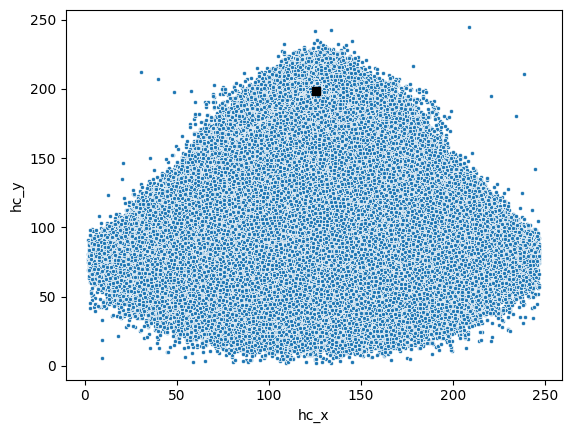

In [15]:
# there isn't spray angle already in statcast --> use hc_x and hc_y to estimate it
# formula: arctan( (hc_x - 125.42) / (198.27 - hc_y) ) * 180/pi * 3/4
# -> the 125.42 and 198.27 represent where home plate is in the inverted hc_x, hc_y pixel coords
# -> the 3/4 is a scaler to make -45º be towards the third base line and 45º towards the first base line

plt.figure()
sns.scatterplot(data=batted_balls[(~batted_balls['hc_x'].isna()) & (~batted_balls['hc_y'].isna())], x='hc_x', y='hc_y', marker='.')
plt.plot(125.42, 198.27, 'ks',)
plt.show()

## because hc_x and hc_y are the hit coord - where the fielder touched the ball - the spray angle is inherently the bearing
batted_balls['spray_angle'] = np.arctan((batted_balls['hc_x'] - 125.42) / (198.27 - batted_balls['hc_y'])) * (180/np.pi) * 0.75

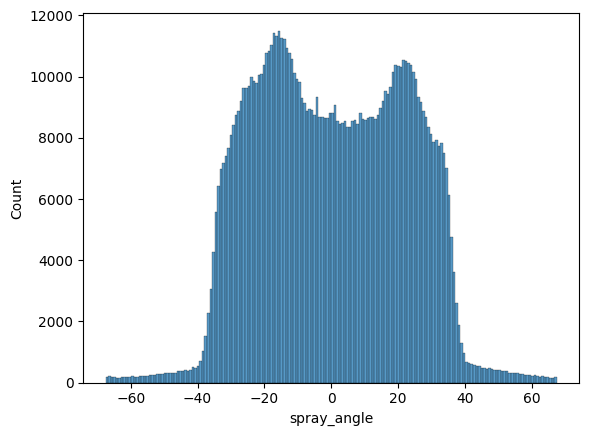

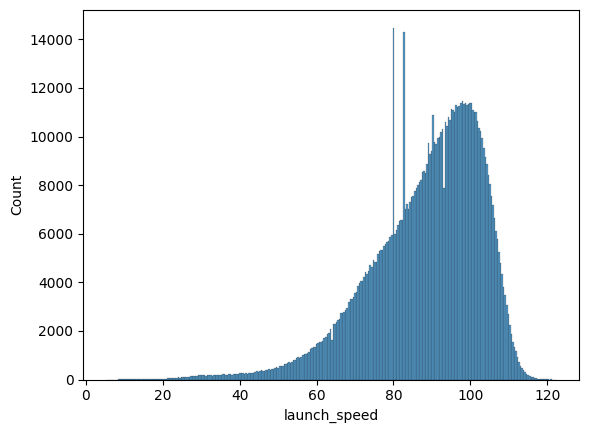

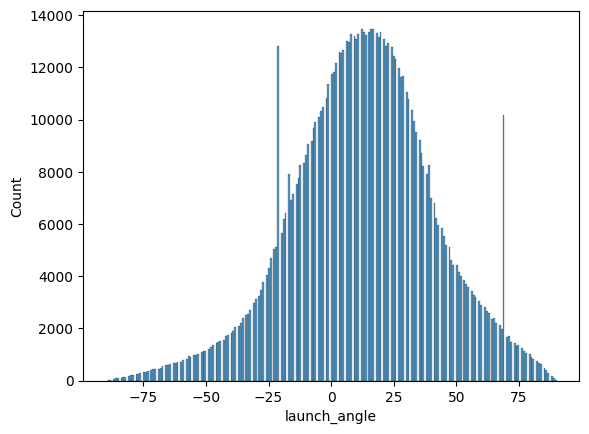

In [16]:
plt.figure()
sns.histplot(data=batted_balls, x='spray_angle')
plt.show()

plt.figure()
sns.histplot(data=batted_balls, x='launch_speed')
plt.show()

plt.figure()
sns.histplot(data=batted_balls, x='launch_angle')
plt.show()

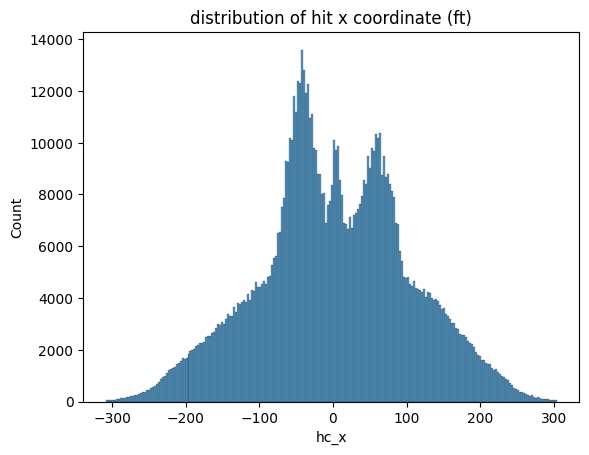

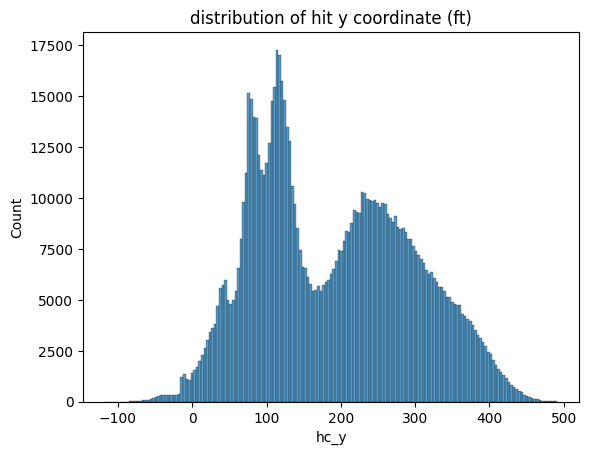

In [17]:
plt.figure()
sns.histplot(batted_balls['hc_x'].apply(lambda x: (x - 125.42) * 2.5))
plt.title('distribution of hit x coordinate (ft)')
plt.show()

plt.figure()
sns.histplot(batted_balls['hc_y'].apply(lambda x: (198.27 - x) * 2.5))
plt.title('distribution of hit y coordinate (ft)')
plt.show()

batted_balls['hc_x'] = batted_balls['hc_x'].apply(lambda x: (x - 125.42) * 2.5)
batted_balls['hc_y'] = batted_balls['hc_y'].apply(lambda x: (198.27 - x) * 2.5)

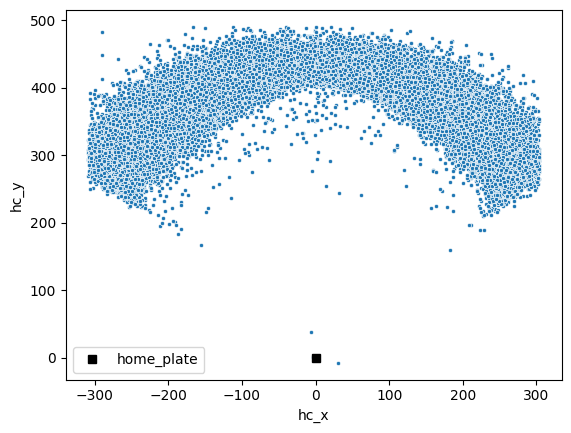

In [18]:
# wanna see the hit coordinates of HRs

hr_balls = batted_balls[(~batted_balls['hc_x'].isna()) & (~batted_balls['hc_y'].isna()) & (batted_balls['events'] == 'home_run')]

plt.figure()
sns.scatterplot(data=hr_balls, x='hc_x', y='hc_y', marker='.')
plt.plot(0, 0, 'ks', label='home_plate')
plt.legend()
plt.show()

In [19]:
batted_balls['hc_y'].describe()

count   900739.000000
mean       190.947777
std        105.140601
min       -116.525000
25%        104.550000
50%        184.725000
75%        272.850000
max        490.350000
Name: hc_y, dtype: float64

In [20]:
batted_balls['hit_distance_sc'].isna().sum()

np.int64(18249)

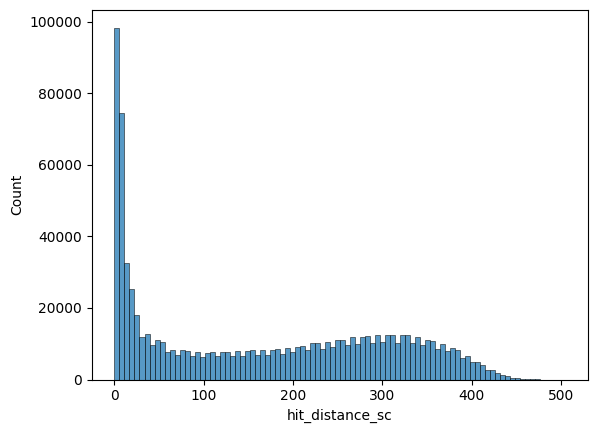

count   882490.000000
mean       166.480453
std        136.452054
min          0.000000
25%         20.000000
50%        160.000000
75%        290.000000
max        505.000000
Name: hit_distance_sc, dtype: float64

In [21]:
plt.figure()
sns.histplot(data=batted_balls, x='hit_distance_sc')
plt.show()

batted_balls['hit_distance_sc'].describe()

obviously there is some discrepancy between `hit_distance_sc` and the translated `hc_y` given the max for one was 505 and the other was 490
* because `hit_distance_sc` is the projected distance when the ball is expected to land and `hc_y` is the estimated point when the ball is fielded, i dont technically have the estimated landing point of the ball - the initial landing point 
* but because i estimated the spray angle of that batted ball using the arctan formula and the hit coord vector, i can use polar coord translation to estimate the landing point coord - i.e., using `hit_distance_sc` as the radial distance from the origin and the spray angle as the angle of rotation - such that X ~ rcos(theta), Y ~ rsin(theta)
* first i gotta deal with the missing `hit_distance_sc`, so we'll just model that since we have exit velo + launch angle + spray angle

/Users/buttz/miniforge3/envs/py313/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


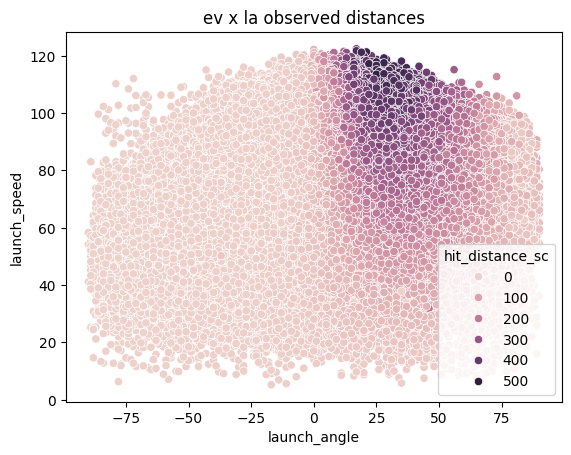

In [22]:
plt.figure()
sns.scatterplot(data=batted_balls[~batted_balls['hit_distance_sc'].isna()], x='launch_angle', y='launch_speed', hue='hit_distance_sc')
plt.title('ev x la observed distances')
plt.show()

In [23]:
batted_balls['bb_type'].value_counts()

bb_type
ground_ball    389446
fly_ball       228190
line_drive     218856
popup           64244
Name: count, dtype: int64

In [24]:
batted_balls['bb_type'].isna().sum() ## it only being 3 means im gonna drop them

np.int64(3)

In [25]:
batted_balls = batted_balls[~batted_balls['bb_type'].isna()].reset_index(drop=True)

In [26]:
# because the statcast leaderboards has a minimum threshold of 10 PAs per situation, 
# there's a lot of missing initial coords, so we'll just take the average per situation (good enough proxy)
# this imputation does create some bias towards the fielders with more appearences observed, but it's fine

for pos in range(3, 7):
    x_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'if_fielding_alignment'])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_if_group_means)
    y_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'if_fielding_alignment'])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_if_group_means)

for pos in range(7, 10):
    x_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'of_fielding_alignment'])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_of_group_means)
    y_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'of_fielding_alignment'])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_of_group_means)

## fills the rest of the missing values
for pos in range(3, 7):
    x_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_if_group_means)
    y_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_if_group_means)

for pos in range(7, 10):
    x_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_of_group_means)
    y_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_of_group_means)

In [27]:
batted_balls[['fielder_3_name', 'fielder_3', 'fielder_3_x', 'fielder_3_y', 
            'fielder_4_name', 'fielder_4', 'fielder_4_x', 'fielder_4_y',
            'fielder_5_name', 'fielder_5', 'fielder_5_x', 'fielder_5_y',
            'fielder_6_name', 'fielder_6', 'fielder_6_x', 'fielder_6_y',
            'fielder_7_name', 'fielder_7', 'fielder_7_x', 'fielder_7_y',
            'fielder_8_name', 'fielder_8', 'fielder_8_x', 'fielder_8_y',
            'fielder_9_name', 'fielder_9', 'fielder_9_x', 'fielder_9_y',]].isna().sum()

fielder_3_name    0
fielder_3         0
fielder_3_x       0
fielder_3_y       0
fielder_4_name    0
fielder_4         0
fielder_4_x       0
fielder_4_y       0
fielder_5_name    0
fielder_5         0
fielder_5_x       0
fielder_5_y       0
fielder_6_name    0
fielder_6         0
fielder_6_x       0
fielder_6_y       0
fielder_7_name    0
fielder_7         0
fielder_7_x       0
fielder_7_y       0
fielder_8_name    0
fielder_8         0
fielder_8_x       0
fielder_8_y       0
fielder_9_name    0
fielder_9         0
fielder_9_x       0
fielder_9_y       0
dtype: int64

In [53]:
# model setup for estimating the missing hit_distance_sc

train_df = batted_balls[~batted_balls['hit_distance_sc'].isna()].copy()
test_df = batted_balls[batted_balls['hit_distance_sc'].isna()].copy()

train_, val_ = train_test_split(train_df, test_size=0.2, stratify=train_df['bb_type'], random_state=42)

X_train = train_[['launch_speed', 'launch_angle', 'spray_angle']].to_numpy(dtype=float)
y_train = train_['hit_distance_sc'].to_numpy(dtype=float)

X_val = val_[['launch_speed', 'launch_angle', 'spray_angle']].to_numpy(dtype=float)
y_val = val_['hit_distance_sc'].to_numpy(dtype=float)

## scaling the train + val set
X_mean = X_train.mean(axis=0)
X_std = np.sqrt(X_train.var(axis=0))

X_train = (X_train - X_mean) / X_std
X_val = (X_val - X_mean) / X_std

In [54]:
X_train[:, :-1]

array([[ 0.92622631,  0.16712505],
       [-0.11200457, -0.54705462],
       [-2.36489772,  1.27410353],
       ...,
       [ 0.74979492,  0.20283403],
       [ 0.96015543, -0.51134564],
       [ 0.19335746, -0.86843547]], shape=(705989, 2))

In [55]:
def distance_model(X_train, y_train, model_name, train_subset):
    """
    trains each model to estimate the batted ball distance
    """
    if model_name == 'gam':
        best_gam = None
        best_gcv = float('inf')
        warnings.filterwarnings("ignore", category=RuntimeWarning)

        ## ev x la features
        if train_subset == 'ev x la':
            spline_candidates = [(i, i) for i in range (4, 11)]
            for splines in spline_candidates:
                try:
                    gam = LinearGAM(te(0, 1, n_splines=splines)).fit(X_train, y_train)
                    gcv = gam.statistics_['GCV']
                    if not np.isnan(gcv) and gcv < best_gcv:
                        best_gcv = gcv
                        best_gam = gam
                except Exception:
                    continue
        
        ## ev x la x sa features
        else:
            spline_candidates = [(i, i, i) for i in range (4, 11)]
            for splines in spline_candidates:
                try:
                    gam = LinearGAM(te(0, 1, 2, n_splines=splines)).fit(X_train, y_train)
                    gcv = gam.statistics_['GCV']
                    if not np.isnan(gcv) and gcv < best_gcv:
                        best_gcv = gcv
                        best_gam = gam
                except Exception:
                    continue

        return best_gam

    elif model_name == 'lr':
        lr_model = sm.OLS(y_train, sm.add_constant(X_train, has_constant='add')).fit()
        print(lr_model.summary())
        return lr_model

    elif model_name == 'xgb':
        xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
        xgb_model.fit(X_train, y_train)
        return xgb_model
    
    elif model_name == 'rf':
        rf_model = RandomForestRegressor(random_state=42)
        rf_model.fit(X_train, y_train)
        return rf_model
        
    else:
        return None

In [56]:
# model results on the validation set -> model selection and evaluation

model_val_results = {}
for model in ['gam', 'lr', 'xgb', 'rf']:
    for train_group in ['ev x la', 'ev x la x sa']:
        print(f'{model}, {train_group}')

        if train_group == 'ev x la':
            X_tr = X_train[:, :-1]
            X_v = X_val[:, :-1]
        else:
            X_tr = X_train
            X_v = X_val

        trained_model = distance_model(X_tr, y_train, model, train_group)

        if model == 'lr':
            train_pred = trained_model.predict(sm.add_constant(X_tr, has_constant='add'))
            val_pred = trained_model.predict(sm.add_constant(X_v, has_constant='add'))
        else:
            train_pred = trained_model.predict(X_tr)
            val_pred = trained_model.predict(X_v)

        ## evaluation metrics
        train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
        train_r2 = r2_score(y_train, train_pred)

        val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        val_r2 = r2_score(y_val, val_pred)

        dict_key = f"{model}_{train_group.replace(' ', '_')}"
        model_val_results[dict_key] = {'model': model, 
                                       'features': train_group, 
                                       'train_rmse': train_rmse, 'train_r2': train_r2, 
                                       'val_rmse': val_rmse, 'val_r2': val_r2
                                       }

model_val_results_df = pd.DataFrame.from_dict(model_val_results, orient='index').reset_index(drop=True)
model_val_results_df

gam, ev x la
gam, ev x la x sa
lr, ev x la
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.502
Model:                            OLS   Adj. R-squared:                  0.502
Method:                 Least Squares   F-statistic:                 3.565e+05
Date:                Wed, 01 Jul 2026   Prob (F-statistic):               0.00
Time:                        18:20:55   Log-Likelihood:            -4.2261e+06
No. Observations:              705989   AIC:                         8.452e+06
Df Residuals:                  705986   BIC:                         8.452e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const    

,model,features,train_rmse,train_r2,val_rmse,val_r2
0,gam,ev x la,19.206155,0.980197,19.118759,0.980333
1,gam,ev x la x sa,18.170527,0.982275,18.135782,0.982303
2,lr,ev x la,96.267187,0.502491,96.368249,0.500317
3,lr,ev x la x sa,96.258644,0.502579,96.357499,0.500428
4,xgb,ev x la,15.927272,0.986382,15.914770,0.986372
5,xgb,ev x la x sa,14.152065,0.989248,14.280581,0.989027
6,rf,ev x la,15.378599,0.987304,16.378888,0.985566
7,rf,ev x la x sa,5.832579,0.998174,15.574102,0.986949


xgboost with ev x la x sa as the features performed the best on the validation set and it didn't overfit that much as the train error is identical to the validation error, so we'll use it
* an error of roughly 15 ft on average seems high but this is across all forms of batted ball, where balls that travel far will have higher error solely due to components that the data doesn't include has an effect - therefore can't include in the model - such as batted ball spin, air/wind conditions of that park on that day, time, etc. -> i could also add the venue as an adjustment - because of coors and t-mobile - however i wanted to focus solely on the conditions that come from the batted ball itself and not external factors that affect ball flight

In [ ]:
# retraining best model on full train set to predict the missing hit_distance_sc values

## combines the train and val sets
X_full = np.vstack([X_train, X_val])
y_full = np.hstack([y_train, y_val])

best_model = distance_model(X_full, y_full, 'xgb', 'ev x la x sa')

## test set
X_test = test_df[['launch_speed', 'launch_angle', 'spray_angle']].to_numpy(dtype=float)
X_test = (X_test - X_mean) / X_std

## creating the pred hit distance
test_df['pred_hit_distance_sc'] = best_model.predict(X_test)
test_df['hit_distance_sc'] = test_df['hit_distance_sc'].fillna(test_df['pred_hit_distance_sc'])

In [67]:
batted_balls = pd.concat([train_df, test_df]).sort_values(by=['game_year', 'game_date', 'game_pk']).drop(columns=['pred_hit_distance_sc']).reset_index(drop=True).copy()

In [ ]:
# estimates the landing coordinate of the batted ball - where the ball would land on the field for the first time

batted_balls['X_coord'] = batted_balls['hit_distance_sc'] * np.cos((90 - batted_balls['spray_angle']) * (np.pi/180))
batted_balls['Y_coord'] = batted_balls['hit_distance_sc'] * np.sin((90 - batted_balls['spray_angle']) * (np.pi/180))

In [74]:
# maps the events to a more general outcome - basically turns all the niche events to just be outs if they're outs 

events_dict = {'single': 'single', 'double': 'double', 'triple': 'triple', 'home_run': 'home_run', \
               'field_out': 'out', 'force_out': 'out', 'grounded_into_double_play': 'out', \
               'sac_fly': 'out', 'field_error': 'error', 'sac_bunt': 'out', 'double_play': 'out', \
               'fielders_choice': 'error', 'fielders_choice_out': 'out', 'sac_fly_double_play': 'out', \
               'triple_play': 'out', 'sac_bunt_double_play': 'out',
               }
batted_balls['events'] = batted_balls['events'].map(events_dict)

In [77]:
batted_balls

,game_pk,game_year,game_date,description,events,bb_type,p_throws,player_name,batter,stand,release_speed,release_pos_x,release_pos_y,release_pos_z,release_extension,vx0,vy0,vz0,ax,ay,az,plate_x,plate_z,on_1b,on_2b,on_3b,runners_on,base_state,launch_speed,launch_angle,effective_speed,hit_distance_sc,hc_x,hc_y,hit_location,if_fielding_alignment,of_fielding_alignment,if_shifted,of_shifted,fielding_team,fielder_3_name,fielder_3,fielder_3_x,fielder_3_y,fielder_4_name,fielder_4,fielder_4_x,fielder_4_y,fielder_5_name,fielder_5,fielder_5_x,fielder_5_y,fielder_6_name,fielder_6,fielder_6_x,fielder_6_y,fielder_7_name,fielder_7,fielder_7_x,fielder_7_y,fielder_8_name,fielder_8,fielder_8_x,fielder_8_y,fielder_9_name,fielder_9,fielder_9_x,fielder_9_y,venue_id,venue_name,spray_angle
0,529407,2018,2018-03-29,hit_into_play,triple,fly_ball,L,"Lester, Jon",518618,L,91.600000,2.810000,54.240000,5.630000,6.300000,-9.691488,-132.833430,-4.411090,9.708662,35.497697,-14.714874,-0.516424,2.702158,0,0,0,0,000,95.600000,30.000000,90.300000,362.000000,-222.625000,311.900000,8,Standard,Standard,0,0,CHC,"Rizzo, Anthony",519203,76.342023,97.713333,"Báez, Javier",595879,46.970583,144.560590,"Bryant, Kris",592178,-54.500000,94.396769,"Russell, Addison",608365,-29.002967,149.207332,"Schwarber, Kyle",656941,-139.625171,251.890476,"Happ, Ian",664023,-16.747506,319.561451,"Heyward, Jason",518792,139.433054,262.235435,4169,loanDepot park,-26.638593
1,529407,2018,2018-03-29,hit_into_play,out,ground_ball,L,"Lester, Jon",518618,L,88.900000,2.710000,53.500000,5.640000,7.000000,-7.767461,-129.475612,-3.598453,15.303278,23.705597,-26.142947,0.628508,2.176360,0,0,0,0,000,93.400000,-12.000000,90.600000,9.000000,53.525000,121.625000,4,Standard,Standard,0,0,CHC,"Rizzo, Anthony",519203,76.342023,97.713333,"Báez, Javier",595879,46.970583,144.560590,"Bryant, Kris",592178,-54.500000,94.396769,"Russell, Addison",608365,-29.002967,149.207332,"Schwarber, Kyle",656941,-139.625171,251.890476,"Happ, Ian",664023,-16.747506,319.561451,"Heyward, Jason",518792,139.433054,262.235435,4169,loanDepot park,17.815081
2,529407,2018,2018-03-29,hit_into_play,home_run,fly_ball,R,"Ureña, José",664023,L,95.500000,-1.580000,54.660000,6.050000,5.800000,7.766284,-138.716117,-6.034276,-19.220056,31.500366,-16.732196,0.242677,2.533997,0,0,0,0,000,107.000000,31.000000,94.500000,392.000000,269.500000,319.475000,<NA>,Standard,Standard,0,0,MIA,"Bour, Justin",571506,72.648054,92.985269,"Castro, Starlin",516770,48.835223,141.827786,"Anderson, Brian",605119,-49.763986,93.592445,"Rojas, Miguel",500743,-21.432658,152.501283,"Dietrich, Derek",518618,-147.300889,245.149848,"Brinson, Lewis",621446,-22.322072,319.220496,"Cooper, Garrett",643265,141.780412,266.650173,4169,loanDepot park,30.112518
3,529407,2018,2018-03-29,hit_into_play,home_run,fly_ball,R,"Guerrero, Tayron",656941,L,96.500000,-2.000000,53.820000,6.370000,6.700000,8.693449,-140.123949,-8.319465,-17.072354,34.027617,-14.887006,0.275864,2.148124,0,0,0,0,000,107.200000,27.000000,96.700000,406.000000,164.350000,396.950000,<NA>,Infield shift,Standard,1,0,MIA,"Bour, Justin",571506,77.777301,92.691378,"Castro, Starlin",516770,65.083212,139.571399,"Anderson, Brian",605119,-6.541995,124.828692,"Rojas, Miguel",500743,-2.635313,150.977002,"Dietrich, Derek",518618,-147.300889,245.149848,"Brinson, Lewis",621446,-22.322072,319.220496,"Cooper, Garrett",643265,141.780412,266.650173,4169,loanDepot park,16.868340
4,529407,2018,2018-03-29,hit_into_play,out,fly_ball,L,"O'Grady, Chris",518792,L,88.000000,2.820000,54.550000,6.890000,6.000000,-5.888235,-127.366239,-9.261315,-0.248815,34.322594,-11.579489,0.219652,1.893324,0,0,0,0,000,99.300000,29.000000,85.900000,363.000000,92.900000,356.325000,8,Infield shift,Standard,1,0,MIA,"Bour, Justin",571506,77.777301,92.691378,"Castro, Starlin",516770,65.083212,139.571399,"Anderson, Brian",605119,-6.541995,124.828692,"Rojas, Miguel",500743,-2.635313,150.977002,"Dietrich, Derek",518618,-147.300889,245.149848,"Brinson, Lewis",621446,-22.3